# Data Profiling & Preprocessing: Spotify Tracks Dataset

Notebook ini melakukan **profiling dataset** dan **preprocessing** untuk persiapan pemodelan *Clustering Mood/Vibe* secara sistematis.

---

### Bagian I — Exploratory Data Analysis (EDA)
1. Import Library & Load Data
2. Struktur Data (Shape, Tipe Kolom, Pratinjau)
3. Statistik Deskriptif
4. Kualitas Data (Missing Values, Duplikasi, Konsistensi, Outlier)
5. Relasi Antar Variabel (Univariat, Bivariat, Multivariat)
6. Ringkasan Temuan EDA

### Bagian II — Preprocessing untuk Clustering (Mood & Vibe)
7. Data Cleaning (Missing Value, Deduplikasi, Filter Anomali)
8. Feature Selection
9. Feature Scaling (StandardScaler)
10. Ringkasan Data Siap Modeling


---
# BAGIAN I — EXPLORATORY DATA ANALYSIS (EDA)
---


## 1. Import Library & Load Data

Mengimpor seluruh library yang dibutuhkan dan memuat dataset ke dalam DataFrame pandas.


In [ ]:
# Import library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', None)
sns.set_style('whitegrid')


### Upload & Muat Dataset

Upload file CSV melalui Google Colab, lalu muat ke dalam DataFrame `df`.


In [ ]:
# Upload dataset (Google Colab)
from google.colab import files

uploaded = files.upload()  # pilih file CSV Anda di sini
filename = list(uploaded.keys())[0]
print(f"File terupload: {filename}")


Saving spotify-tracks-dataset-detailed.csv to spotify-tracks-dataset-detailed.csv
File terupload: spotify-tracks-dataset-detailed.csv


In [ ]:
# Muat dataset ke DataFrame
df = pd.read_csv(filename)
print(f"Dataset berhasil dimuat: {df.shape[0]:,} baris, {df.shape[1]} kolom")


Dataset berhasil dimuat: 114,000 baris, 20 kolom


## 2. Struktur Data

Memahami bentuk dasar dataset: ukuran tabel, tipe data setiap kolom, dan pratinjau isi data.


### 2.1 Dimensi Dataset

Menampilkan format penyimpanan file serta jumlah baris (observasi) dan kolom (variabel).


In [ ]:
print(f"Format file     : CSV (tabular)")
print(f"Jumlah baris    : {df.shape[0]:,}  (records/observations)")
print(f"Jumlah kolom    : {df.shape[1]}  (features/variables)")


Format file     : CSV (tabular)
Jumlah baris    : 114,000  (records/observations)
Jumlah kolom    : 20  (features/variables)


### 2.2 Pratinjau Data (5 Baris Pertama)

Menampilkan 5 baris pertama dataset untuk memahami struktur dan isi data secara visual.


In [ ]:
df.head()


,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,1,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,1,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,0,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,0,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,2,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


### 2.3 Informasi Tipe Data & Non-Null Count

Ringkasan tipe data setiap kolom beserta jumlah nilai non-null. Berguna untuk mendeteksi missing value dan memahami tipe penyimpanan data.


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 20 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   track_id          114000 non-null  object 
 1   artists           113999 non-null  object 
 2   album_name        113999 non-null  object 
 3   track_name        113999 non-null  object 
 4   popularity        114000 non-null  int64  
 5   duration_ms       114000 non-null  int64  
 6   explicit          114000 non-null  bool   
 7   danceability      114000 non-null  float64
 8   energy            114000 non-null  float64
 9   key               114000 non-null  int64  
 10  loudness          114000 non-null  float64
 11  mode              114000 non-null  int64  
 12  speechiness       114000 non-null  float64
 13  acousticness      114000 non-null  float64
 14  instrumentalness  114000 non-null  float64
 15  liveness          114000 non-null  float64
 16  valence           11

### 2.4 Klasifikasi Kolom: Numerik vs Kategorikal

Mengklasifikasikan setiap kolom sebagai **Numerik** atau **Kategorikal** berdasarkan tipe datanya, lengkap dengan contoh nilai.


In [ ]:
klasifikasi = ['Numerik' if pd.api.types.is_numeric_dtype(df[c]) else 'Kategorikal' for c in df.columns]
pd.DataFrame({
    'kolom': df.columns,
    'tipe_data': df.dtypes.values,
    'jenis_data': klasifikasi,
    'contoh_nilai': [df[col].dropna().iloc[0] if df[col].notna().any() else None for col in df.columns]
})


,kolom,tipe_data,jenis_data,contoh_nilai
0,track_id,object,Kategorikal,5SuOikwiRyPMVoIQDJUgSV
1,artists,object,Kategorikal,Gen Hoshino
2,album_name,object,Kategorikal,Comedy
3,track_name,object,Kategorikal,Comedy
4,popularity,int64,Numerik,73
5,duration_ms,int64,Numerik,230666
6,explicit,bool,Numerik,False
7,danceability,float64,Numerik,0.676
8,energy,float64,Numerik,0.461
9,key,int64,Numerik,1


## 3. Statistik Deskriptif

Statistik ringkas untuk kolom numerik dan kategorikal.


### 3.1 Statistik Kolom Numerik

Menghitung count, mean, std, min, Q1, median, Q3, max untuk semua kolom numerik.


In [ ]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
popularity,114000.0,33.238535,22.305078,0.000,17.00000,35.000000,50.0000,100.000
duration_ms,114000.0,228029.153114,107297.712645,0.000,174066.00000,212906.000000,261506.0000,5237295.000
danceability,114000.0,0.566800,0.173542,0.000,0.45600,0.580000,0.6950,0.985
energy,114000.0,0.641383,0.251529,0.000,0.47200,0.685000,0.8540,1.000
key,114000.0,5.309140,3.559987,0.000,2.00000,5.000000,8.0000,11.000
loudness,114000.0,-8.258960,5.029337,-49.531,-10.01300,-7.004000,-5.0030,4.532
mode,114000.0,0.637553,0.480709,0.000,0.00000,1.000000,1.0000,1.000
speechiness,114000.0,0.084652,0.105732,0.000,0.03590,0.048900,0.0845,0.965
acousticness,114000.0,0.314910,0.332523,0.000,0.01690,0.169000,0.5980,0.996
instrumentalness,114000.0,0.156050,0.309555,0.000,0.00000,0.000042,0.0490,1.000


### 3.2 Statistik Kolom Kategorikal

Menghitung count, unique, top (nilai terbanyak), dan freq (frekuensinya) untuk kolom bertipe teks.


In [ ]:
df.describe(include='object').T


,count,unique,top,freq
track_id,114000,89741,6S3JlDAGk3uu3NtZbPnuhS,9
artists,113999,31437,The Beatles,279
album_name,113999,46589,Alternative Christmas 2022,195
track_name,113999,73608,Run Rudolph Run,151
track_genre,114000,114,acoustic,1000


### 3.3 Kardinalitas (Jumlah Nilai Unik per Kolom)

Menghitung jumlah nilai unik setiap kolom. Kolom dengan kardinalitas sangat tinggi mungkin bersifat identifier.


In [ ]:
df.nunique().sort_values(ascending=False).to_frame('jumlah_nilai_unik')


,jumlah_nilai_unik
track_id,89741
track_name,73608
duration_ms,50697
album_name,46589
tempo,45653
artists,31437
loudness,19480
instrumentalness,5346
acousticness,5061
energy,2083


### 3.4 Visualisasi Distribusi Fitur Numerik Utama

Histogram untuk fitur-fitur numerik utama guna memahami bentuk dan sebaran distribusinya.


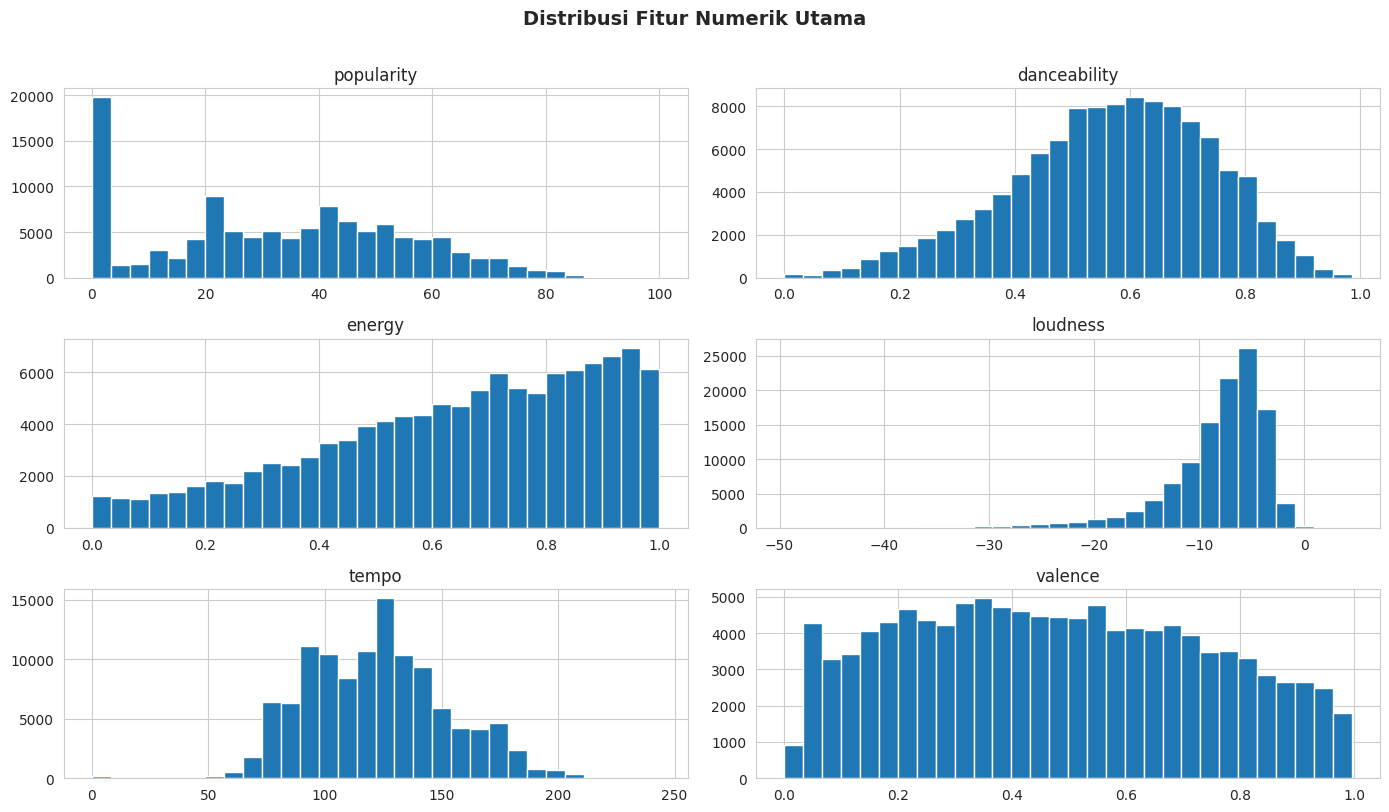

In [ ]:
numeric_cols = ['popularity', 'danceability', 'energy', 'loudness', 'tempo', 'valence']
df[numeric_cols].hist(bins=30, figsize=(14, 8))
plt.suptitle('Distribusi Fitur Numerik Utama', y=1.01, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()


## 4. Kualitas Data

Mengecek kelengkapan, keunikan, konsistensi, dan keberadaan outlier pada dataset.


### 4.1 Missing Values

Menghitung jumlah dan persentase missing value di setiap kolom.


In [ ]:
missing = df.isnull().sum()
missing_pct = (missing / len(df)) * 100
missing_df = pd.DataFrame({'jumlah_missing': missing, 'persentase (%)': missing_pct.round(2)})
missing_df


,jumlah_missing,persentase (%)
track_id,0,0.0
artists,1,0.0
album_name,1,0.0
track_name,1,0.0
popularity,0,0.0
duration_ms,0,0.0
explicit,0,0.0
danceability,0,0.0
energy,0,0.0
key,0,0.0


### 4.2 Duplikasi Baris

Mengecek jumlah baris duplikat secara keseluruhan maupun berdasarkan `track_id`.


In [ ]:
# Duplikasi baris (semua kolom identik)
jumlah_duplikat = df.duplicated().sum()
print(f"Jumlah baris duplikat (semua kolom identik): {jumlah_duplikat}")

# Duplikasi berdasarkan track_id
dup_track_id = df['track_id'].duplicated().sum()
print(f"Jumlah track_id duplikat                   : {dup_track_id}")


Jumlah baris duplikat (semua kolom identik): 450
Jumlah track_id duplikat                   : 24259


### 4.3 Keunikan & Interpretasi Kardinalitas

Menghitung rasio keunikan setiap kolom dan menginterpretasikannya — apakah bersifat identifier, kategorikal, konstan, atau campuran.


In [ ]:
tabel_keunikan = pd.DataFrame({
    'jumlah_unik': df.nunique(),
    'total_baris': len(df),
    'rasio_unik (%)': (df.nunique() / len(df) * 100).round(2)
})

def interpretasi_keunikan(rasio, jumlah_unik):
    if jumlah_unik == 1:
        return 'Konstan (1 nilai saja)'
    elif rasio >= 95:
        return 'Identifier / hampir semua unik'
    elif rasio <= 5:
        return 'Kategorikal (nilai berulang)'
    else:
        return 'Campuran'

tabel_keunikan['interpretasi'] = tabel_keunikan.apply(
    lambda row: interpretasi_keunikan(row['rasio_unik (%)'], row['jumlah_unik']), axis=1
)
tabel_keunikan


,jumlah_unik,total_baris,rasio_unik (%),interpretasi
track_id,89741,114000,78.72,Campuran
artists,31437,114000,27.58,Campuran
album_name,46589,114000,40.87,Campuran
track_name,73608,114000,64.57,Campuran
popularity,101,114000,0.09,Kategorikal (nilai berulang)
duration_ms,50697,114000,44.47,Campuran
explicit,2,114000,0.00,Kategorikal (nilai berulang)
danceability,1174,114000,1.03,Kategorikal (nilai berulang)
energy,2083,114000,1.83,Kategorikal (nilai berulang)
key,12,114000,0.01,Kategorikal (nilai berulang)


### 4.4 Konsistensi & Validitas Nilai

Mengecek apakah nilai fitur audio berada dalam rentang yang valid.


#### Validasi Rentang Fitur Audio [0, 1]

Fitur ternormalisasi seperti `danceability`, `energy`, dll. seharusnya berada dalam rentang [0, 1].


In [ ]:
fitur_01 = ['danceability', 'energy', 'speechiness', 'acousticness',
            'instrumentalness', 'liveness', 'valence']

for col in fitur_01:
    diluar_rentang = df[(df[col] < 0) | (df[col] > 1)]
    print(f"{col:18s}: min={df[col].min():.4f}, max={df[col].max():.4f}, "
          f"nilai di luar [0,1] = {len(diluar_rentang)}")


danceability      : min=0.0000, max=0.9850, nilai di luar [0,1] = 0
energy            : min=0.0000, max=1.0000, nilai di luar [0,1] = 0
speechiness       : min=0.0000, max=0.9650, nilai di luar [0,1] = 0
acousticness      : min=0.0000, max=0.9960, nilai di luar [0,1] = 0
instrumentalness  : min=0.0000, max=1.0000, nilai di luar [0,1] = 0
liveness          : min=0.0000, max=1.0000, nilai di luar [0,1] = 0
valence           : min=0.0000, max=0.9950, nilai di luar [0,1] = 0


#### Validasi Kolom Popularity & Duration

Mengecek rentang `popularity` (0–100) dan mendeteksi lagu dengan durasi janggal.


In [ ]:
print("Popularity - min:", df['popularity'].min(), "| max:", df['popularity'].max())
print("Jumlah popularity = 0:", (df['popularity'] == 0).sum())

print("\nDurasi (ms) - min:", df['duration_ms'].min(), "| max:", df['duration_ms'].max())
print("Jumlah lagu dengan durasi 0:", (df['duration_ms'] == 0).sum())
print("Jumlah lagu dengan durasi < 10 detik:", (df['duration_ms'] < 10000).sum())


Popularity - min: 0 | max: 100
Jumlah popularity = 0: 16020

Durasi (ms) - min: 0 | max: 5237295
Jumlah lagu dengan durasi 0: 1
Jumlah lagu dengan durasi < 10 detik: 2


### 4.5 Deteksi Outlier (Metode IQR)

Menggunakan metode **Interquartile Range (IQR)** untuk mendeteksi outlier pada kolom numerik utama. Nilai di luar batas Q1 - 1.5 x IQR dan Q3 + 1.5 x IQR dianggap outlier.


In [ ]:
def deteksi_outlier_iqr(data, kolom):
    Q1 = data[kolom].quantile(0.25)
    Q3 = data[kolom].quantile(0.75)
    IQR = Q3 - Q1
    batas_bawah = Q1 - 1.5 * IQR
    batas_atas = Q3 + 1.5 * IQR
    outlier = data[(data[kolom] < batas_bawah) | (data[kolom] > batas_atas)]
    return len(outlier), batas_bawah, batas_atas

kolom_cek_outlier = ['duration_ms', 'tempo', 'loudness', 'popularity']
for kolom in kolom_cek_outlier:
    jumlah, bawah, atas = deteksi_outlier_iqr(df, kolom)
    print(f"{kolom:15s}: {jumlah} outlier (batas normal: {bawah:.2f} s/d {atas:.2f})")


duration_ms    : 5617 outlier (batas normal: 42906.00 s/d 392666.00)
tempo          : 617 outlier (batas normal: 37.94 s/d 201.35)
loudness       : 6173 outlier (batas normal: -17.53 s/d 2.51)
popularity     : 2 outlier (batas normal: -32.50 s/d 99.50)


#### Visualisasi Outlier dengan Boxplot

Menampilkan boxplot untuk kolom yang dianalisis outlier-nya.


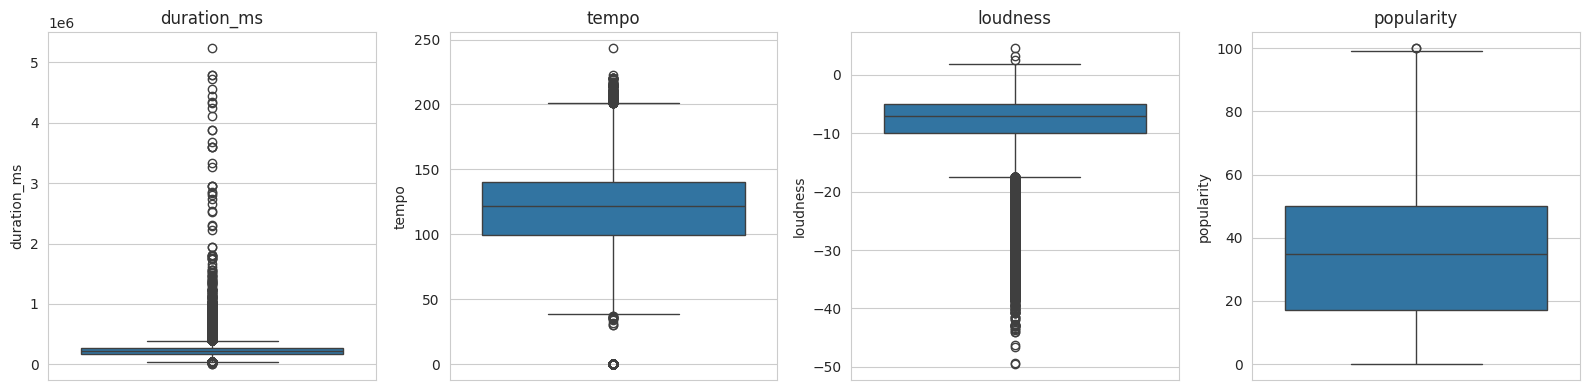

In [ ]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, kolom in zip(axes, kolom_cek_outlier):
    sns.boxplot(y=df[kolom], ax=ax)
    ax.set_title(kolom)
plt.tight_layout()
plt.show()


### 4.6 Konsistensi Kolom Boolean `explicit`

Mengecek distribusi nilai kolom `explicit` (True/False) untuk memastikan konsistensi.


In [ ]:
print(df['explicit'].value_counts(dropna=False))


explicit
False    104253
True       9747
Name: count, dtype: int64


## 5. Relasi Antar Variabel

Analisis hubungan antar kolom: univariat (distribusi masing-masing), bivariat (dua variabel), dan multivariat (banyak variabel sekaligus).


### 5.1 Univariat — Skewness & Distribusi

Mengukur kemencengan (skewness) distribusi tiap variabel numerik. Nilai mendekati 0 = simetris, |skewness| > 1 = distribusi sangat menjulang.


In [ ]:
kolom_korelasi = ['popularity', 'danceability', 'energy', 'loudness', 'speechiness',
                   'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo']

skewness = df[kolom_korelasi].skew().sort_values(key=abs, ascending=False)
print("Skewness tiap variabel (mendekati 0 = simetris, >1 atau <-1 = menjulang kuat):")
print(skewness)


Skewness tiap variabel (mendekati 0 = simetris, >1 atau <-1 = menjulang kuat):
speechiness         4.647516
liveness            2.105738
loudness           -2.006542
instrumentalness    1.734406
acousticness        0.727295
energy             -0.597001
danceability       -0.399497
tempo               0.232295
valence             0.115078
popularity          0.046403
dtype: float64


#### Visualisasi Distribusi per Variabel

Histogram + KDE untuk semua variabel numerik, diurutkan berdasarkan tingkat skewness paling ekstrem.


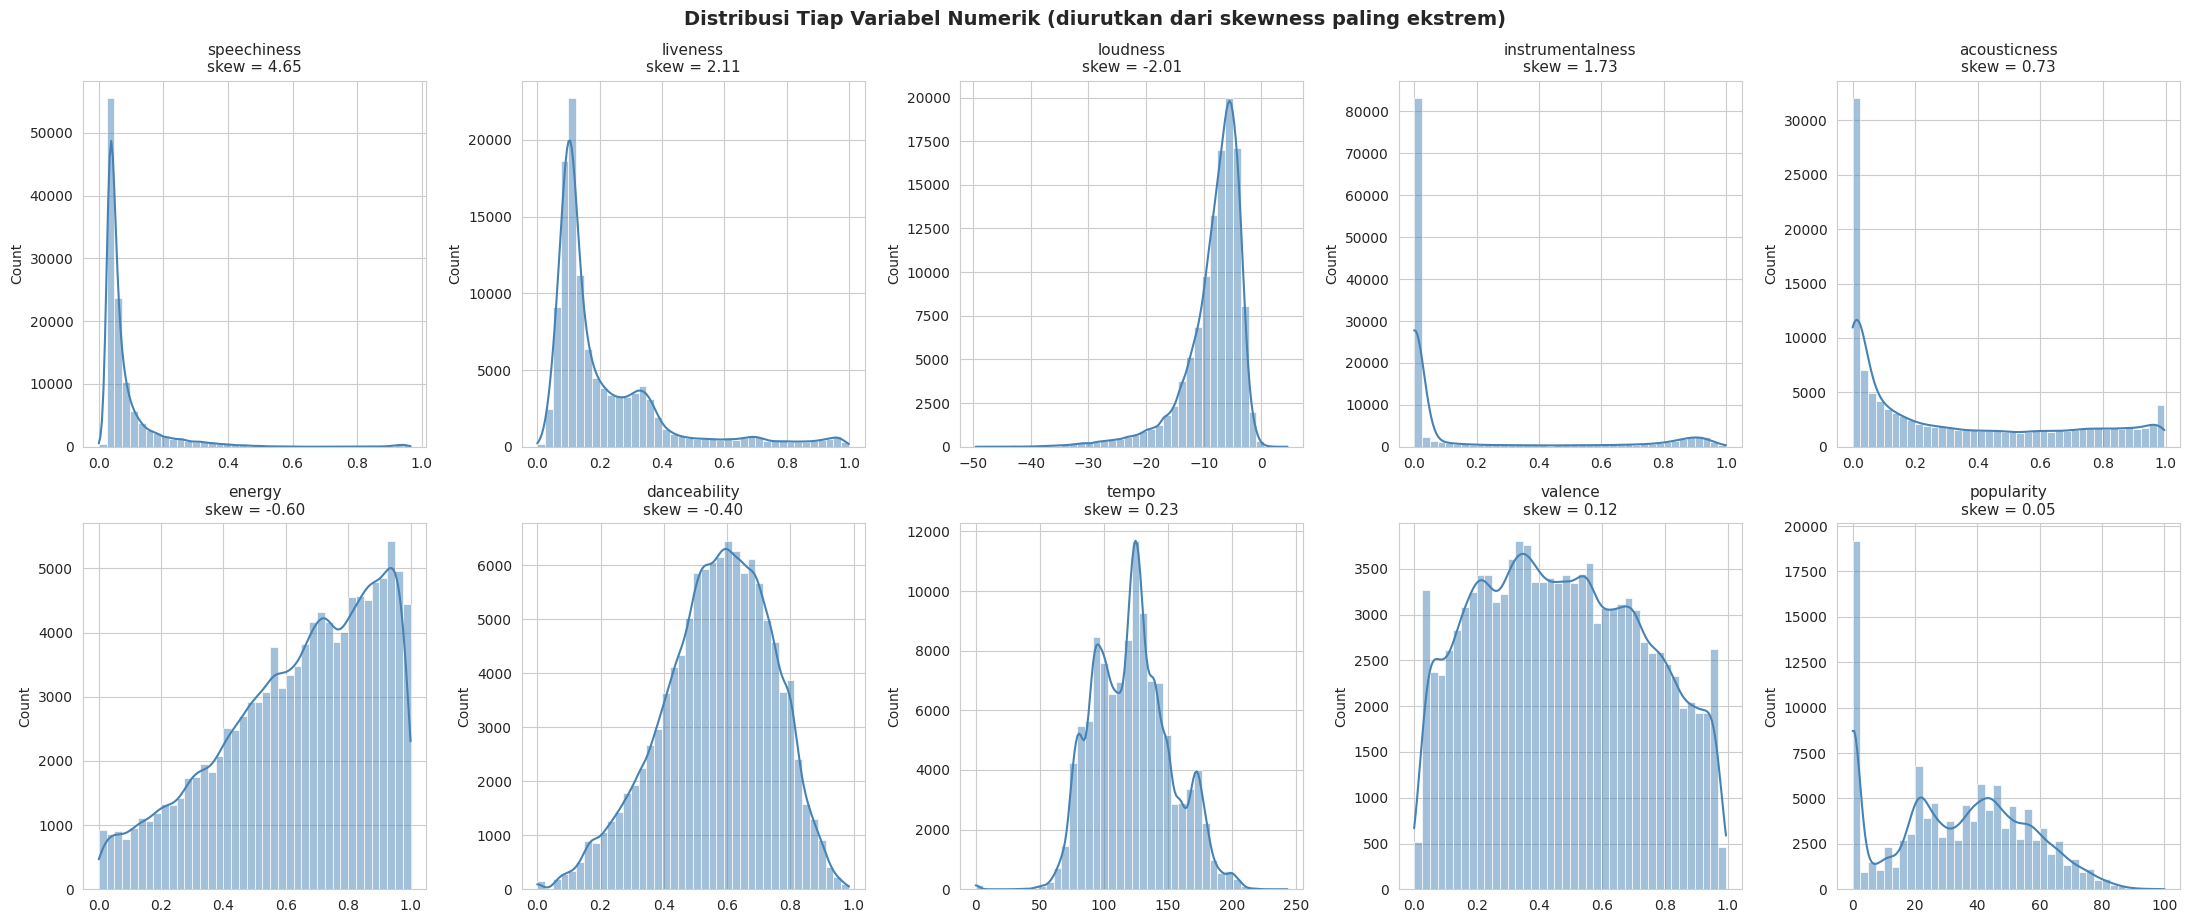

In [ ]:
fig, axes = plt.subplots(2, 5, figsize=(22, 9))
axes = axes.flatten()

for ax, kolom in zip(axes, skewness.index):
    sns.histplot(df[kolom], bins=40, kde=True, ax=ax, color='steelblue')
    ax.set_title(f"{kolom}\nskew = {skewness[kolom]:.2f}", fontsize=11)
    ax.set_xlabel('')

plt.tight_layout()
plt.suptitle('Distribusi Tiap Variabel Numerik (diurutkan dari skewness paling ekstrem)',
             y=1.02, fontsize=14, fontweight='bold')
plt.show()


### 5.2 Bivariat — Hubungan Antar Dua Variabel

Scatter plot untuk melihat hubungan antara `energy` dan `loudness` (sampel 3.000 baris).


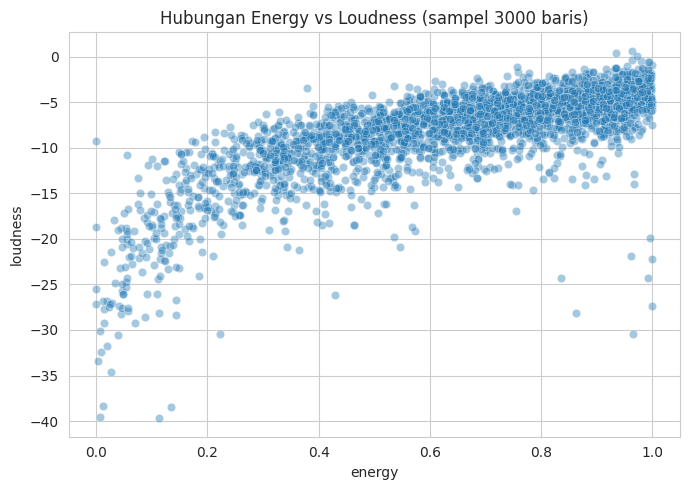

In [ ]:
plt.figure(figsize=(7, 5))
sns.scatterplot(data=df.sample(3000, random_state=42), x='energy', y='loudness', alpha=0.4)
plt.title('Hubungan Energy vs Loudness (sampel 3000 baris)')
plt.tight_layout()
plt.show()


### 5.3 Multivariat — Matriks Korelasi

Heatmap korelasi Pearson antar semua fitur audio numerik.


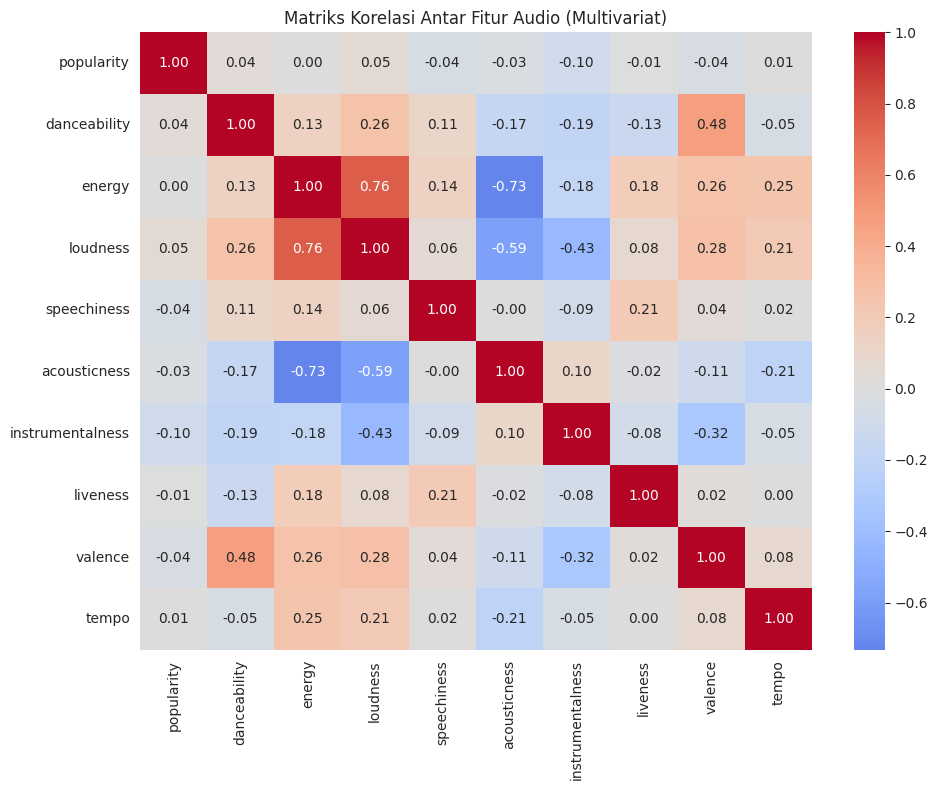

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df[kolom_korelasi].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Matriks Korelasi Antar Fitur Audio (Multivariat)')
plt.tight_layout()
plt.show()


### 5.4 Tabel Korelasi Pearson (dengan p-value)

Tabel korelasi Pearson antar pasangan kolom numerik beserta **p-value** untuk mengetahui signifikansi statistiknya.


In [ ]:
from scipy.stats import pearsonr

hasil = []
for i, col1 in enumerate(kolom_korelasi):
    for col2 in kolom_korelasi[i+1:]:
        data_bersih = df[[col1, col2]].dropna()
        r, p = pearsonr(data_bersih[col1], data_bersih[col2])
        hasil.append({
            'Variabel 1': col1,
            'Variabel 2': col2,
            'Koefisien Pearson (r)': round(r, 4),
            'p-value': round(p, 6),
            'Signifikan (a=0.05)': 'Ya' if p < 0.05 else 'Tidak'
        })

tabel_korelasi = pd.DataFrame(hasil).sort_values('Koefisien Pearson (r)', key=abs, ascending=False)
tabel_korelasi


,Variabel 1,Variabel 2,Koefisien Pearson (r),p-value,Signifikan (a=0.05)
17,energy,loudness,0.7617,0.000000,Ya
19,energy,acousticness,-0.7339,0.000000,Ya
25,loudness,acousticness,-0.5898,0.000000,Ya
15,danceability,valence,0.4773,0.000000,Ya
26,loudness,instrumentalness,-0.4335,0.000000,Ya
40,instrumentalness,valence,-0.3243,0.000000,Ya
28,loudness,valence,0.2798,0.000000,Ya
10,danceability,loudness,0.2591,0.000000,Ya
22,energy,valence,0.2589,0.000000,Ya
23,energy,tempo,0.2479,0.000000,Ya


## 6. Ringkasan Temuan EDA

Rekap temuan utama dari seluruh proses profiling.


In [ ]:
print("=" * 60)
print("RINGKASAN PROFIL DATASET")
print("=" * 60)
print(f"Jumlah baris                : {df.shape[0]:,}")
print(f"Jumlah kolom                : {df.shape[1]}")
print(f"Jumlah genre unik           : {df['track_genre'].nunique()}")
print(f"Jumlah artis unik           : {df['artists'].nunique()}")
print(f"Total missing values        : {df.isnull().sum().sum()}")
print(f"Baris duplikat (semua kolom): {df.duplicated().sum()}")
print(f"track_id duplikat           : {df['track_id'].duplicated().sum()}")
print(f"Rentang popularity          : {df['popularity'].min()} - {df['popularity'].max()}")
print(f"Rentang durasi (menit)      : {df['duration_ms'].min()/60000:.2f} - {df['duration_ms'].max()/60000:.2f}")
print("=" * 60)


RINGKASAN PROFIL DATASET
Jumlah baris                : 114,000
Jumlah kolom                : 20
Jumlah genre unik           : 114
Jumlah artis unik           : 31437
Total missing values        : 3
Baris duplikat (semua kolom): 450
track_id duplikat           : 24259
Rentang popularity          : 0 - 100
Rentang durasi (menit)      : 0.00 - 87.29


---
# BAGIAN II — PREPROCESSING UNTUK CLUSTERING (MOOD & VIBE)

Pada bagian ini, data yang sudah dieksplorasi di Bagian I dipersiapkan agar siap dimasukkan ke dalam algoritma K-Means.

Langkah-langkah preprocessing:
1. **Data Cleaning**: Hapus missing values, deduplikasi `track_id`, filter anomali durasi/tempo.
2. **Feature Selection**: Pilih 9 fitur audio pembentuk mood/vibe.
3. **Feature Scaling**: Standarisasi seluruh fitur menggunakan `StandardScaler`.
---


## 7. Data Cleaning

Membersihkan data dari missing values, duplikasi `track_id`, dan anomali sebelum masuk ke tahap feature selection.


### 7.1 Hapus Missing Values

Menghapus baris yang memiliki nilai kosong pada kolom metadata lagu.


In [ ]:
# Cek missing values
print("Missing values per kolom:")
print(df.isnull().sum()[df.isnull().sum() > 0])

# Hapus baris dengan missing value
df_clean = df.dropna(subset=['track_name', 'artists', 'album_name']).copy()
print(f"\nBaris setelah hapus missing value: {len(df_clean):,}")


Missing values per kolom:
artists       1
album_name    1
track_name    1
dtype: int64

Baris setelah hapus missing value: 113,999


### 7.2 Deduplikasi `track_id`

Satu lagu yang sama sering tercatat berulang karena terdaftar di beberapa genre berbeda. Setiap track unik hanya dipertahankan satu kali agar tidak memboboti klaster.


In [ ]:
total_duplikat = df_clean['track_id'].duplicated().sum()
print(f"Jumlah track_id duplikat: {total_duplikat:,}")

df_clean = df_clean.drop_duplicates(subset=['track_id'], keep='first').copy()
print(f"Lagu unik tersisa: {len(df_clean):,} baris")


Jumlah track_id duplikat: 24,259
Lagu unik tersisa: 89,740 baris


### 7.3 Filter Anomali Durasi & Tempo

Menghapus track dengan durasi < 30 detik (sound effect/audio rusak) dan tempo 0 BPM (tanpa ketukan ritme).


In [ ]:
anomali_durasi = (df_clean['duration_ms'] < 30000).sum()
anomali_tempo = (df_clean['tempo'] <= 0).sum()

print(f"Track durasi < 30 detik : {anomali_durasi}")
print(f"Track tempo <= 0 BPM    : {anomali_tempo}")

df_clean = df_clean[(df_clean['duration_ms'] >= 30000) & (df_clean['tempo'] > 0)].copy()
print(f"\nData valid setelah pembersihan: {len(df_clean):,} baris")


Track durasi < 30 detik : 14
Track tempo <= 0 BPM    : 157

Data valid setelah pembersihan: 89,571 baris


## 8. Feature Selection

Memilih 9 fitur audio kontinu yang merepresentasikan mood/vibe musik:

| Fitur | Deskripsi |
|---|---|
| `danceability` | Kesesuaian ritme untuk berdansa |
| `energy` | Intensitas dan keaktifan lagu |
| `loudness` | Volume rata-rata (dB) |
| `speechiness` | Keberadaan kata-kata lisan |
| `acousticness` | Kadar instrumen akustik |
| `instrumentalness` | Dominasi instrumen tanpa vokal |
| `liveness` | Rekaman live vs studio |
| `valence` | Positivitas emosional |
| `tempo` | Kecepatan ketukan (BPM) |

> **Tidak disertakan**: `popularity` (bukan sifat musik), `key` & `mode` (kategorikal nominal), metadata teks, dan `track_genre` (disimpan untuk evaluasi pasca-clustering).


In [ ]:
mood_features = [
    'danceability', 'energy', 'loudness', 'speechiness',
    'acousticness', 'instrumentalness', 'liveness', 'valence', 'tempo'
]

X = df_clean[mood_features].copy()
print(f"Dimensi matriks fitur: {X.shape}")
X.head()


Dimensi matriks fitur: (89571, 9)


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.676,0.4610,-6.746,0.1430,0.0322,0.000001,0.3580,0.715,87.917
1,0.420,0.1660,-17.235,0.0763,0.9240,0.000006,0.1010,0.267,77.489
2,0.438,0.3590,-9.734,0.0557,0.2100,0.000000,0.1170,0.120,76.332
3,0.266,0.0596,-18.515,0.0363,0.9050,0.000071,0.1320,0.143,181.740
4,0.618,0.4430,-9.681,0.0526,0.4690,0.000000,0.0829,0.167,119.949


## 9. Feature Scaling (StandardScaler)

K-Means menghitung jarak Euclidean antar titik data. Tanpa standarisasi, fitur berskala besar (`tempo`: 50–240, `loudness`: -50 s/d 5) akan mendominasi perhitungan jarak, sementara fitur penentu mood (`valence`, `acousticness`: 0–1) menjadi tidak berpengaruh.

**StandardScaler** mentransformasikan setiap fitur menjadi z-score sehingga memiliki rata-rata = 0 dan standar deviasi = 1.


In [ ]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=mood_features, index=df_clean.index)
X_scaled_df.head()


,danceability,energy,loudness,speechiness,acousticness,instrumentalness,liveness,valence,tempo
0,0.643774,-0.682084,0.333727,0.489182,-0.874760,-0.534037,0.727862,0.932649,-1.156520
1,-0.816918,-1.835847,-1.692494,-0.099576,1.763081,-0.534023,-0.594598,-0.775024,-1.507556
2,-0.714213,-1.081012,-0.243482,-0.281411,-0.348848,-0.534040,-0.512266,-1.335355,-1.546504
3,-1.695616,-2.251984,-1.939759,-0.452654,1.706881,-0.533822,-0.435080,-1.247684,2.001826
4,0.312836,-0.752483,-0.233244,-0.308775,0.417244,-0.534040,-0.687736,-1.156201,-0.078233


### 9.1 Verifikasi Hasil Standarisasi

Memastikan seluruh fitur kini memiliki mean = 0 dan std = 1.


In [ ]:
verifikasi = pd.DataFrame({
    'Mean': X_scaled_df.mean().round(6),
    'Std': X_scaled_df.std().round(4),
})
verifikasi


,Mean,Std
danceability,-0.0,1.0
energy,0.0,1.0
loudness,-0.0,1.0
speechiness,0.0,1.0
acousticness,-0.0,1.0
instrumentalness,0.0,1.0
liveness,0.0,1.0
valence,-0.0,1.0
tempo,-0.0,1.0


## 10. Ringkasan Data Siap Modeling

Rekapitulasi kondisi dataset setelah seluruh proses preprocessing selesai.


In [ ]:
df_clean.reset_index(drop=True, inplace=True)
X_scaled_df.reset_index(drop=True, inplace=True)

print("=" * 65)
print("RINGKASAN AKHIR PREPROCESSING")
print("=" * 65)
print(f"Baris dataset awal             : {df.shape[0]:,}")
print(f"Baris data bersih (siap pakai) : {df_clean.shape[0]:,}")
print(f"Baris tereliminasi             : {df.shape[0] - df_clean.shape[0]:,}")
print(f"Jumlah fitur mood              : {len(mood_features)}")
print(f"Dimensi matriks X_scaled       : {X_scaled.shape}")
print("=" * 65)
print("\nData telah bersih dan terstandarisasi. Siap untuk modeling K-Means!")


RINGKASAN AKHIR PREPROCESSING
Baris dataset awal             : 114,000
Baris data bersih (siap pakai) : 89,571
Baris tereliminasi             : 24,429
Jumlah fitur mood              : 9
Dimensi matriks X_scaled       : (89571, 9)

Data telah bersih dan terstandarisasi. Siap untuk modeling K-Means!


## Langkah Selanjutnya: Modeling K-Means

Dengan matriks fitur terstandarisasi (`X_scaled`), langkah berikutnya:
1. **Mencari k optimal** dengan Elbow Method dan Silhouette Score.
2. **Melatih model K-Means** dengan k terpilih.
3. **Visualisasi PCA 2D** untuk melihat sebaran klaster.
4. **Profiling vibe musik (Radar Chart)** untuk memberi label setiap klaster.
